<a href="https://colab.research.google.com/github/Bruno-Bras/modelos-preditivos-de-churn/blob/main/Arthur_e_Bruno_RNA_2025_2_PP1_2.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

## Atividade Avaliativa 1.2 - _Churn Prediction_

- Redes Neurais Artificiais 2026.2
- Profa. Elloá B. Guedes
- http://github.com/elloa

### Equipe

- Arthur Marshall Cavalcante Rezende (https://github.com/ArthurMarshallCavalcanteRezende)
- Bruno Brás Barros (https://github.com/brunobrasbarros)

### Recomendação Importante

A realização desse exercício deve ser feita em duplas de de forma livre durante as aulas, com acompanhamento da professora, utilizando a linguagem Python no ambiente Google Colab. A versão final deve ser depositada no Google Classroom na data estabelecida para a atividade. Os alunos podem consultar a documentação de todos os pacotes recomendados, livros, materiais de apoio e afins. Dissuade-se definitivamente o uso de IA Generativa para a elaboração de respostas, análise e síntese de hípoteses, bem como para a geração automática de código. A entrega dessa atividade contemplará apenas 10% da avaliação do Projeto Prático 1.2. Os 90% restantes da nota serão aferidos por meio de uma prova escrita individual, sem consulta, sobre os elementos contidos decorrentes do desenvolvimento do projeto, cujo conhecimento será de domínio daqueles estudantes que tiverem se empenhado na realização da tarefa.

### Apresentação

A previsão de evasão de clientes (_Churn Prediction_) é um problema tipicamente abordado pela Ciência de Dados com o uso de modelos de _Machine Learning_ para identificar clientes com alta probabilidade de descontinuar o uso de um serviço ou produto. Possui extrema importância para o domínio de negócios, especialmente para empresas com modelos de receita baseados em assinatura (SaaS, telecomunicações, serviços de streaming) ou que dependem da fidelidade do cliente, especialmente por:

1. **Impacto na Receita e Lucratividade.** O custo de adquirir um novo cliente é, em geral, significativamente maior do que o custo de reter um cliente existente. A evasão de clientes (churn) representa uma perda direta de receita recorrente. Ao prever quais clientes estão em risco, as empresas podem intervir com estratégias de retenção direcionadas, como ofertas especiais ou suporte aprimorado, minimizando essa perda financeira. A retenção de clientes não só protege a receita atual, mas também contribui para o aumento do _Lifetime Value_ do cliente, que é a receita total que um cliente gera ao longo de sua relação com a empresa;
2. **Otimização de Recursos e Estratégias.** Sem um modelo de previsão, as empresas tendem a adotar estratégias de retenção de forma genérica, aplicando os mesmos esforços a todos os clientes, independentemente do risco de evasão. Isso leva a um desperdício de recursos;
3. **Entendimento do Comportamento do Cliente.** A construção de um modelo de previsão de churn exige a análise aprofundada dos dados de comportamento do cliente. Esse processo revela insights valiosos sobre o que leva os clientes a ficarem ou a saírem, o que não apenas ajuda a reter clientes, mas também auxilia o desenvolvimento de produtos, a melhoria do serviço e a criação de estratégias de marketing mais eficazes para atrair clientes com um perfil de maior lealdade.

### Contexto do Problema

O termo _Telco_ se refere a _telecommunications industry_. Este domínio é particularmente relevante para a análise de churn devido ao seu alto nível de competição e saturação. Os clientes neste setor — seja para serviços de telefonia móvel, internet ou TV a cabo — têm uma vasta gama de provedores à sua escolha, o que torna relativamente fácil para eles migrarem caso estejam insatisfeitos ou encontrem uma oferta melhor.

### Base de Dados

Base de dados original: https://www.kaggle.com/datasets/blastchar/telco-customer-churn

### Bibliotecas

Por hábito, a primeira célula do notebook costuma ser reservada para importação de bibliotecas.
A cada biblioteca nova acrescida, é necessário executar a célula para atualização e correta execução.

In [ ]:
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np
import sklearn as skl

## Parte 1 - Análise e Exploração de Dados

### Abertura do Dataset
Abra o dataset e visualize o seu cabeçalho, isto é, os primeiros exemplos nele contidos. Isto é útil para checar se a importação foi realizada de maneira adequada e se a disposição dos dados está de acordo para os próximos passos do trabalho.

In [ ]:
df = pd.read_csv("WA_Fn-UseC_-Telco-Customer-Churn.csv")
df.head()

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.50,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


### Conhecendo o dataset

Para praticar conceitos relativos à exploração do conjunto de dados, utilize as células a seguir para prover respostas para cada uma das respostas elencadas

#### Quantos exemplos há no dataset?

In [ ]:
df.shape

(7043, 21)

#### Dados Faltantes

- Elimine todas as entradas em que há dados faltantes
- Qual o decréscimo percentual no tamanho do dataset?

Tratar strings válidas em branco

In [ ]:
df["TotalCharges"] = pd.to_numeric(df["TotalCharges"], errors="coerce")

Eliminar entradas com dados faltantes

In [ ]:
# Registrar tamanho original
tam_original = len(df)

df.isna().sum()

# dropna = elimina linha com dado faltante
df_limpo = df.dropna()

# Registrar tamanho pós limpeza
tam_limpo = len(df_limpo)

Decréscimo percentual

In [ ]:
decrescimo = (tam_original - tam_limpo) / tam_original * 100
print(f"{decrescimo:.2f}%")

0.16%


#### Dados Duplicados

- Verifique se há clientes duplicados (mesmo id é repetido)
- Em caso afirmativo, elimine as duplicatas, favorecendo as entradas mais recentes

In [ ]:
coluna_id = 'customerID'
if df.duplicated(subset=[coluna_id]).any():
    df.drop_duplicates(subset=[coluna_id], keep='last', inplace=True)
    print("Duplicatas removidas mantendo os registros mais recentes.")
else:
    print("Não foram encontradas duplicatas.")

Não foram encontradas duplicatas.


#### Quais os atributos existentes no dataset e seu tipo?

- Exemplos de tipos de dados são categóricos (nominal ou ordinal), numéricos (discreto ou contínuo), textual ou estampa de tempo. Faça uma análise e agrupe por categoria na sua resposta. Observe que analisar os tipos das variáveis não é suficiente.

In [ ]:
tabela_de_classificacao = {
    "customerID":       "Identificador",
    "gender":            "Nominal",
    "SeniorCitizen":     "Nominal",
    "Partner":           "Nominal",
    "Dependents":        "Nominal",
    "tenure":            "Discreto",
    "PhoneService":      "Nominal",
    "MultipleLines":     "Nominal",
    "InternetService":   "Nominal",
    "OnlineSecurity":    "Nominal",
    "OnlineBackup":      "Nominal",
    "DeviceProtection":  "Nominal",
    "TechSupport":       "Nominal",
    "StreamingTV":       "Nominal",
    "StreamingMovies":   "Nominal",
    "Contract":          "Ordinal",
    "PaperlessBilling":  "Nominal",
    "PaymentMethod":     "Nominal",
    "MonthlyCharges":    "Contínuo",
    "TotalCharges":      "Contínuo",
    "Churn":             "Nominal",
}

tabela_tipos = pd.DataFrame({
    "Atributo": df.columns,
    "Dtype (pandas)": df.dtypes.astype(str).values,
    "Nº valores únicos": df.nunique().values,
    "Categoria": [tabela_de_classificacao[col] for col in df.columns],
})

print(tabela_tipos)

resumo = tabela_tipos.groupby("Categoria").agg(
    Quantidade=("Atributo", "count"),
    Atributos=("Atributo", lambda x: list(x))
)
print(resumo)

            Atributo Dtype (pandas)  Nº valores únicos      Categoria
0         customerID         object               7043  Identificador
1             gender         object                  2        Nominal
2      SeniorCitizen          int64                  2        Nominal
3            Partner         object                  2        Nominal
4         Dependents         object                  2        Nominal
5             tenure          int64                 73       Discreto
6       PhoneService         object                  2        Nominal
7      MultipleLines         object                  3        Nominal
8    InternetService         object                  3        Nominal
9     OnlineSecurity         object                  3        Nominal
10      OnlineBackup         object                  3        Nominal
11  DeviceProtection         object                  3        Nominal
12       TechSupport         object                  3        Nominal
13       StreamingTV

Justificativa: Não há atributos do tipo estampa de tempo nem textual (texto livre) neste dataset.
Não existem colunas de data/hora, e todas as colunas de texto representam categorias de
vocabulário fechado (ou seja, admitem poucos valores possíveis), e não texto livre.

**Identificadores / Texto**

* `customerID`: Código único do cliente (sem valor preditivo direto).

**Dados Categóricos — Nominais**

* `gender`: Sexo do cliente.
* `SeniorCitizen`: Flag binária ($0$ ou $1$). Embora esteja como `int64`, é conceitualmente categórica nominal.
* `Partner`, `Dependents`, `PhoneService`, `PaperlessBilling`, `Churn`: Binários (*Yes/No*).
* `MultipleLines`, `OnlineSecurity`, `OnlineBackup`, `DeviceProtection`, `TechSupport`, `StreamingTV`, `StreamingMovies`: Múltiplas categorias (*Yes*, *No*, *No internet/phone service*).
* `InternetService`: Tipo de serviço (*DSL*, *Fiber optic*, *No*).
* `PaymentMethod`: Método de pagamento (*Electronic check*, *Mailed check*, etc.).

**Dados Categóricos — Ordinais**

* `Contract`: Possui hierarquia clara de tempo e fidelidade (*Month-to-month* < *One year* < *Two year*).

**Dados Numéricos — Discretos**

* `tenure`: Contagem inteira de meses em que o cliente permanece na empresa.

**Dados Numéricos — Contínuos**

* `MonthlyCharges`: Valor mensal em ponto flutuante (`float64`).
* `TotalCharges`: Valor acumulado em ponto flutuante (`float64`). *(Obs: apresenta 11 valores ausentes/nulos em relação ao total de 7043 registros)*.

**Estampas de Tempo**

* Nenhuma coluna do tipo data/hora (`datetime`) presente no conjunto atual.


#### Qual cliente paga o maior valor de assinatura mensal e que não faz streaming de filmes?

- Apresente o valor pago mensalmente e os demais atributos desse cliente

In [ ]:
df.loc[df[df['StreamingMovies'] != 'Yes']['MonthlyCharges'].idxmax()]

,5544
customerID,9572-MTILT
gender,Male
SeniorCitizen,0
Partner,Yes
Dependents,No
tenure,59
PhoneService,Yes
MultipleLines,Yes
InternetService,Fiber optic
OnlineSecurity,Yes


#### Histograma do tempo de permanência

O histograma é um gráfico que mostra as frequências de uma determinada informação. No nosso caso, vamos construir histogramas que mostram o tempo de permanência no serviço (tenure). Vamos agrupar os valores em bins, cujo número deve ser definido pela Regra de Sturges.

- Plote dois histogramas, um para os clientes que evadiram do serviço e outro para os que continuaram sua assinatura
- Rotule os eixos e utilize boas práticas de visualização da informação
- Faça a seguinte análise: as distribuições são diferentes?

Documentação completa disponível em: https://matplotlib.org/stable/api/_as_gen/matplotlib.pyplot.hist.html


Regra de Sturges: k = [1+log2(n)]

In [ ]:
evadiram = df.loc[df["Churn"] == "Yes", "tenure"]
continuaram = df.loc[df["Churn"] == "No", "tenure"]

n = df["tenure"].shape[0]
k = int(np.ceil(1 + np.log2(n)))

# Valores em bins
bins = np.linspace(df["tenure"].min(), df["tenure"].max(), k + 1)

Plote dois histogramas:

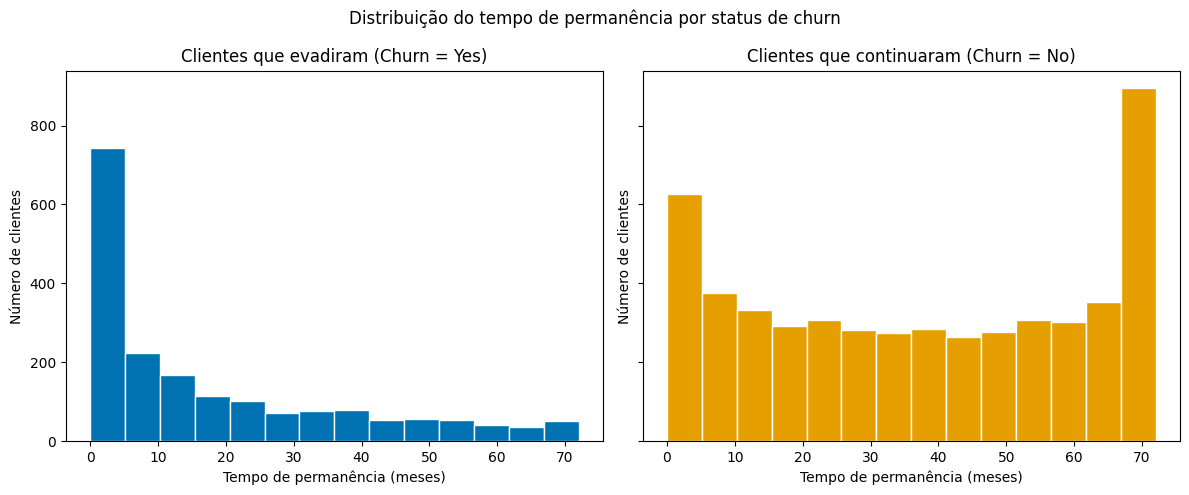

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5), sharey=True)

axes[0].hist(evadiram, bins=bins, color="#0072B2", edgecolor="white")
axes[0].set_title("Clientes que evadiram (Churn = Yes)")
axes[0].set_xlabel("Tempo de permanência (meses)")
axes[0].set_ylabel("Número de clientes")

axes[1].hist(continuaram, bins=bins, color="#E69F00", edgecolor="white")
axes[1].set_title("Clientes que continuaram (Churn = No)")
axes[1].set_xlabel("Tempo de permanência (meses)")
axes[1].set_ylabel("Número de clientes")

fig.suptitle("Distribuição do tempo de permanência por status de churn")
plt.tight_layout()
plt.show()

Análise:

#### Boxplot das Cobranças Mensais

Como é a distribuição das cobranças mensais? O gráfico boxplot pode nos ajudar nesta questão.

O boxplot ilustra informações importantes:
- Mediana
- Limite inferior (menor valor)
- Limite superior (maior valor)
- Q1 (primeiro quartil, 25% dos dados)
- Q3 (terceiro quartil, 75% dos dados)
- Outliers (se houver)

A distribuição dos exemplos no dataset é simétrica no tocante ao atributo em questão? Elabore um parágrafo que justifique as conclusões obtidas a partir da análise do boxplot.

Documentação completa disponível em: https://matplotlib.org/stable/api/_as_gen/matplotlib.pyplot.boxplot.html

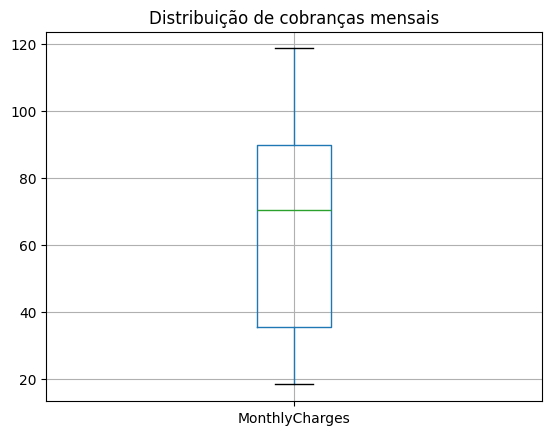

Q1: 35.50
Q3: 89.85
Mediana: 70.35


In [ ]:
menor_valor = df['MonthlyCharges'].min()
q1 = df['MonthlyCharges'].quantile(0.25)
mediana = df['MonthlyCharges'].median()
q3 = df['MonthlyCharges'].quantile(0.75)
maior_valor = df['MonthlyCharges'].max()

df.boxplot("MonthlyCharges")
plt.title('Distribuição de cobranças mensais')
plt.show()

print(f"Q1: {q1:.2f}")
print(f"Q3: {q3:.2f}")
print(f"Mediana: {mediana:.2f}")

Justificação:

#### Taxa de Churn

- Qual a taxa de churn para cada perfil de tipo de pagamento mensal? Há diferenças?

In [ ]:
pd.crosstab(df['PaymentMethod'], df['Churn'], normalize='index')

Churn,No,Yes
PaymentMethod,,
Bank transfer (automatic),0.832902,0.167098
Credit card (automatic),0.847569,0.152431
Electronic check,0.547146,0.452854
Mailed check,0.808933,0.191067


#### Avaliação de Hipóteses

Analise as seguintes hipóteses, elaborando gráficos e consulta aos dados para embasar suas justificativas:

- Hipótese 1: "Clientes que optaram por serviços como TechSupport (suporte técnico) têm uma probabilidade menor de churn."
- Hipótese 2: "A taxa de churn é significativamente maior para clientes com contratos de curto prazo em comparação com aqueles com contratos de longo prazo."
- Hipótese 3: "Clientes com múltiplos serviços, com dependentes e que fazem backup online possuem baixa probabilidade de trocar de prestadora"

Hipótese 1:

In [ ]:
com_internet = df[df['InternetService'] != 'No']

contagem_h1 = com_internet.groupby('TechSupport')['Churn'].count()
taxa_h1 = com_internet.groupby('TechSupport')['Churn'].apply(lambda s: (s == 'Yes').mean())
tabela_h1 = pd.DataFrame({'n_clientes': contagem_h1, 'taxa_churn': taxa_h1})
tabela_h1 = tabela_h1.sort_values('taxa_churn', ascending=False)
tabela_h1

,n_clientes,taxa_churn
TechSupport,,
No,3473,0.416355
Yes,2044,0.151663


Plotar gráfico

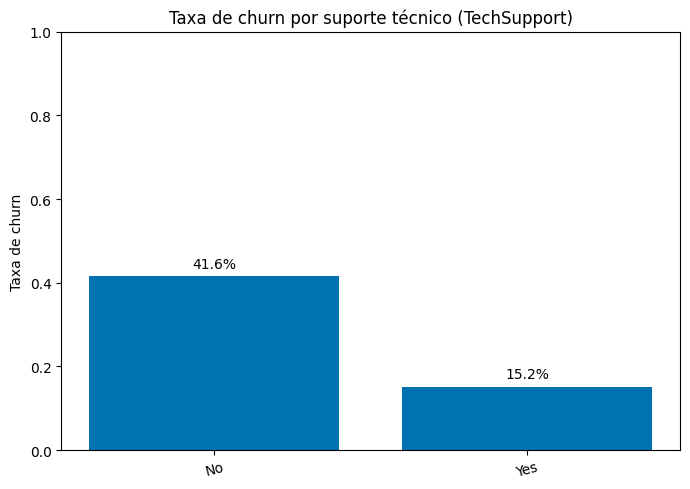

In [ ]:
fig, ax = plt.subplots(figsize=(7, 5))
barras = ax.bar(tabela_h1.index.astype(str), tabela_h1['taxa_churn'], color="#0072B2")
ax.set_ylabel("Taxa de churn")
ax.set_ylim(0, 1)
ax.set_title("Taxa de churn por suporte técnico (TechSupport)")
for barra, taxa in zip(barras, tabela_h1['taxa_churn']):
    ax.text(barra.get_x() + barra.get_width()/2, taxa + 0.02, f"{taxa:.1%}", ha='center')
plt.xticks(rotation=15)
plt.tight_layout()
plt.show()

Justificativa H1: O suporte técnico reduz churn. O gráfico apresenta uma diferença de 26,4% dentre quem não tem suporte técnico (41,6%) para os que tem (15,2%). Hipótese inicial correta.

Hipótese 2:

In [ ]:
contagem_h2 = df.groupby('Contract')['Churn'].count()
taxa_h2 = df.groupby('Contract')['Churn'].apply(lambda s: (s == 'Yes').mean())
tabela_h2 = pd.DataFrame({'n_clientes': contagem_h2, 'taxa_churn': taxa_h2})
ordem_contrato = ['Month-to-month', 'One year', 'Two year']
tabela_h2 = tabela_h2.loc[ordem_contrato]
tabela_h2

,n_clientes,taxa_churn
Contract,,
Month-to-month,3875,0.427097
One year,1473,0.112695
Two year,1695,0.028319


Plotar gráfico

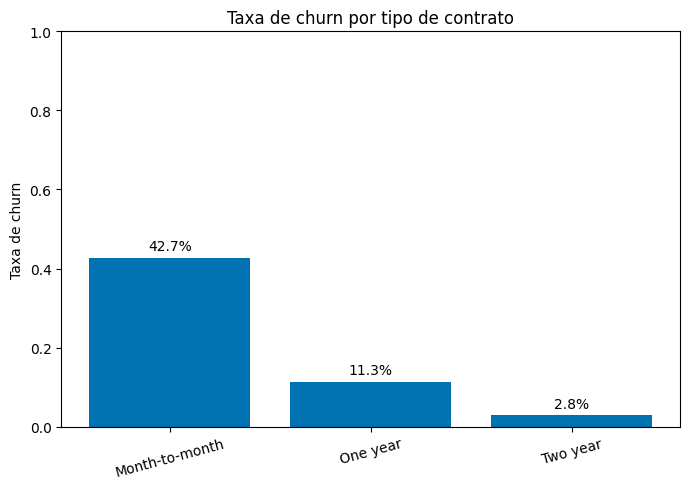

In [ ]:
fig, ax = plt.subplots(figsize=(7, 5))
barras = ax.bar(tabela_h2.index.astype(str), tabela_h2["taxa_churn"], color="#0072B2")
ax.set_ylabel("Taxa de churn")
ax.set_ylim(0, 1)
ax.set_title("Taxa de churn por tipo de contrato")
for barra, taxa in zip(barras, tabela_h2["taxa_churn"]):
    ax.text(barra.get_x() + barra.get_width()/2, taxa + 0.02, f"{taxa:.1%}", ha="center")
plt.xticks(rotation=15)
plt.tight_layout()
plt.show()

Justificativa H2: A taxa de churn possui uma proporção maior em contratos mensais comparado aos contratos de 1 a 2 anos. Hipótese inicial correta.

Hipótese 3:

In [ ]:
# Definição de perfil
perfil = ((df['MultipleLines'] == 'Yes') & (df['Dependents'] == 'Yes') & (df['OnlineBackup'] == 'Yes'))

taxa_h3 = df.groupby(perfil)['Churn'].apply(lambda s: (s == 'Yes').mean())
taxa_h3.index = ['Não atende ao perfil', 'Atende ao perfil completo']
taxa_h3

,Churn
Não atende ao perfil,0.273508
Atende ao perfil completo,0.132678


Plotar Gráfico

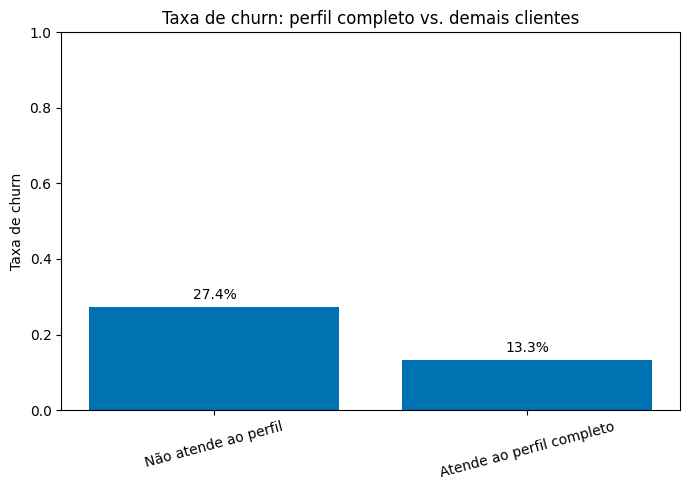

In [ ]:
fig, ax = plt.subplots(figsize=(7, 5))
barras = ax.bar(taxa_h3.index.astype(str), taxa_h3.values, color="#0072B2")
ax.set_ylabel("Taxa de churn")
ax.set_ylim(0, 1)
ax.set_title("Taxa de churn: perfil completo vs. demais clientes")
for barra, taxa in zip(barras, taxa_h3.values):
    ax.text(barra.get_x() + barra.get_width()/2, taxa + 0.02, f"{taxa:.1%}", ha='center')
plt.xticks(rotation=15)
plt.tight_layout()
plt.show()

Justificativa H3: Clientes que atendem ao perfil possuem uma taxa de churn moderadamente menor comparado aos que não atendem ao perfil. Hipótese inicial correta.

#### Perfil do Cliente de Risco

Crie uma série de 3 a 4 gráficos conectados que, juntos, respondam à seguinte pergunta:

_**Qual é o perfil do cliente com alta probabilidade de churn e o que mais o influencia a sair?**_

1. Visualização da Distribuição de Permanência (Tenure)  
- Gráfico: Histograma ou gráfico de densidade comparando o tempo de permanência (tenure) de clientes que saíram (Churn = Yes) com o de clientes que ficaram (Churn = No).
- Objetivo: Mostrar visualmente se o churn é mais comum entre clientes novos ou antigos.

2. Análise da Relação entre Tipo de Contrato e Evasão
- Gráfico: Gráfico de barras agrupadas ou empilhadas que mostre a taxa de churn para cada tipo de contrato (Monthly, One year, Two year).
- Objetivo: Demonstrar o impacto do tipo de contrato na decisão do cliente de sair.

3. Combinação de Variáveis: Preços e Serviços
- Gráfico: Gráfico de dispersão (scatter plot) ou um gráfico de box plot que combine duas variáveis-chave, como MonthlyCharges (cobranças mensais) e o tipo de serviço de internet (InternetService), segmentado pela variável Churn.
- Objetivo: Revelar se clientes que pagam mais por um tipo específico de serviço (ex: Fibra Óptica) têm uma taxa de churn diferente. Isso pode sugerir, por exemplo, que a insatisfação está ligada à qualidade de um serviço mais caro.


Escreva um breve parágrafo resumindo as descobertas. A resposta deve conectar as visualizações, respondendo à pergunta inicial sobre o perfil do cliente em risco de forma coesa e baseada nas evidências visuais.

In [ ]:
df["TotalCharges"] = pd.to_numeric(df["TotalCharges"], errors="coerce")
df = df.dropna(subset=["TotalCharges"])   # 11 linhas em branco (clientes com tenure=0)

COR = {"No": "#4C72B0", "Yes": "#C44E52"}
ficou, saiu = df[df.Churn == "No"], df[df.Churn == "Yes"]
taxa_geral = (df.Churn == "Yes").mean() * 100
print(f"Base: {len(df)} clientes | Churn geral: {taxa_geral:.1f}%")

Base: 7032 clientes | Churn geral: 26.6%


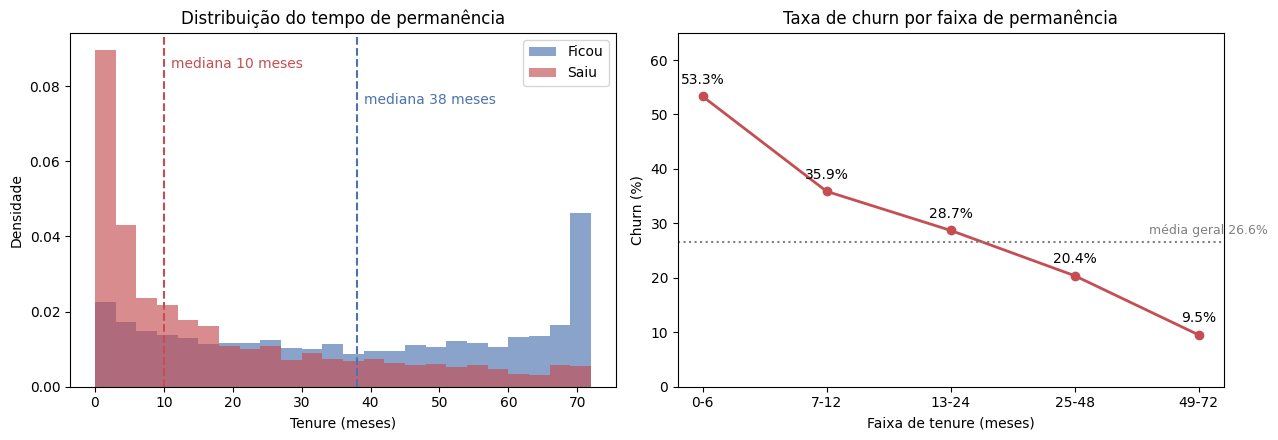

In [ ]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 4.5))

bins = np.arange(0, 75, 3)
ax1.hist(ficou.tenure, bins=bins, alpha=.65, density=True, color=COR["No"], label="Ficou")
ax1.hist(saiu.tenure,  bins=bins, alpha=.65, density=True, color=COR["Yes"], label="Saiu")
ax1.axvline(ficou.tenure.median(), color=COR["No"],  ls="--", lw=1.5)
ax1.axvline(saiu.tenure.median(),  color=COR["Yes"], ls="--", lw=1.5)
ax1.text(saiu.tenure.median()+1, ax1.get_ylim()[1]*.9, "mediana 10 meses", color=COR["Yes"])
ax1.text(ficou.tenure.median()+1, ax1.get_ylim()[1]*.8, "mediana 38 meses", color=COR["No"])
ax1.set_title("Distribuição do tempo de permanência")
ax1.set_xlabel("Tenure (meses)"); ax1.set_ylabel("Densidade"); ax1.legend()

faixas = pd.cut(df.tenure, [-.1, 6, 12, 24, 48, 72],
                labels=["0-6", "7-12", "13-24", "25-48", "49-72"])
taxa = df.groupby(faixas, observed=True).Churn.apply(lambda s: (s == "Yes").mean()) * 100
ax2.plot(taxa.index.astype(str), taxa.values, marker="o", color=COR["Yes"], lw=2)
ax2.axhline(taxa_geral, ls=":", color="gray")
ax2.text(3.6, taxa_geral+1.5, f"média geral {taxa_geral:.1f}%", color="gray", fontsize=9)
for x, y in zip(taxa.index.astype(str), taxa.values):
    ax2.annotate(f"{y:.1f}%", (x, y), textcoords="offset points", xytext=(0, 9), ha="center")
ax2.set_ylim(0, 65)
ax2.set_title("Taxa de churn por faixa de permanência")
ax2.set_xlabel("Faixa de tenure (meses)"); ax2.set_ylabel("Churn (%)")

plt.tight_layout(); plt.show()

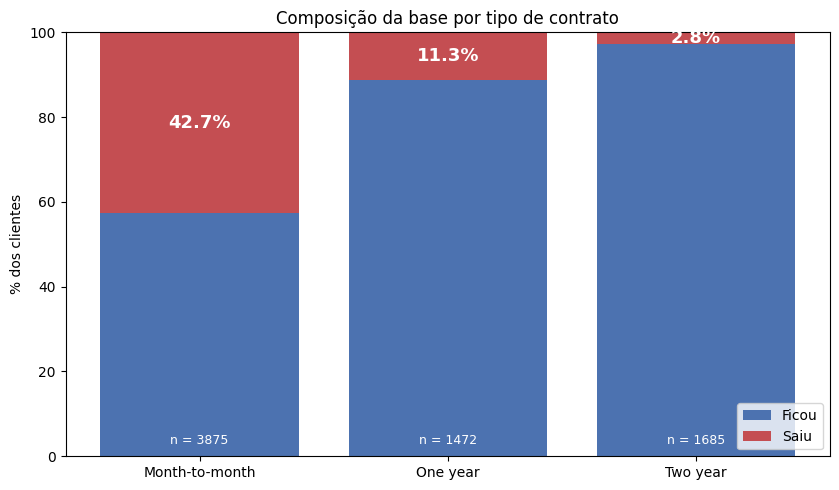

In [ ]:
ct = (pd.crosstab(df.Contract, df.Churn, normalize="index") * 100).loc[
      ["Month-to-month", "One year", "Two year"]]
n = df.Contract.value_counts()

fig, ax = plt.subplots(figsize=(8.5, 5))
ax.bar(ct.index, ct["No"],  color=COR["No"],  label="Ficou")
ax.bar(ct.index, ct["Yes"], bottom=ct["No"], color=COR["Yes"], label="Saiu")
for i, (idx, v) in enumerate(ct["Yes"].items()):
    ax.text(i, 100 - v/2, f"{v:.1f}%", ha="center", va="center",
            color="white", fontweight="bold", fontsize=13)
    ax.text(i, 3, f"n = {n[idx]}", ha="center", color="white", fontsize=9)
ax.set_title("Composição da base por tipo de contrato")
ax.set_ylabel("% dos clientes"); ax.set_ylim(0, 100); ax.legend(loc="lower right")
plt.tight_layout(); plt.show()

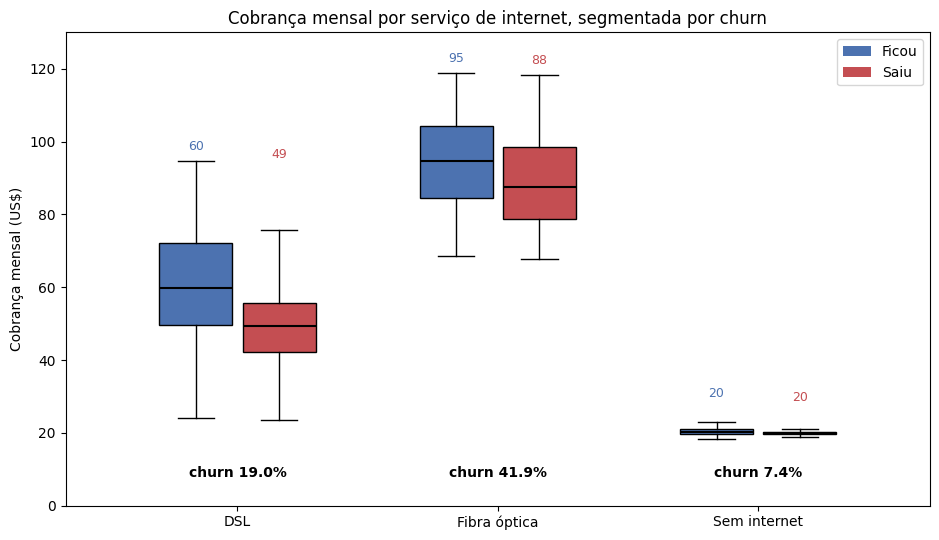

In [ ]:
ordem = ["DSL", "Fiber optic", "No"]
fig, ax = plt.subplots(figsize=(9.5, 5.5))

for i, serv in enumerate(ordem):
    for j, ch in enumerate(["No", "Yes"]):
        d = df[(df.InternetService == serv) & (df.Churn == ch)].MonthlyCharges
        bp = ax.boxplot(d, positions=[i + (j - .5) * .32], widths=.28,
                        patch_artist=True, showfliers=False,
                        medianprops=dict(color="black", lw=1.5))
        bp["boxes"][0].set_facecolor(COR[ch])
        ax.text(i + (j - .5) * .32, d.max() + 3, f"{d.median():.0f}",
                ha="center", fontsize=9, color=COR[ch])

for i, serv in enumerate(ordem):
    r = (df[df.InternetService == serv].Churn == "Yes").mean() * 100
    ax.text(i, 8, f"churn {r:.1f}%", ha="center", fontsize=10, fontweight="bold")

ax.set_xticks(range(len(ordem)))
ax.set_xticklabels(["DSL", "Fibra óptica", "Sem internet"])
ax.set_ylim(0, 130); ax.set_ylabel("Cobrança mensal (US$)")
ax.set_title("Cobrança mensal por serviço de internet, segmentada por churn")
ax.legend(handles=[plt.Rectangle((0,0),1,1,fc=COR["No"]),
                   plt.Rectangle((0,0),1,1,fc=COR["Yes"])],
          labels=["Ficou", "Saiu"], loc="upper right")
plt.tight_layout(); plt.show()

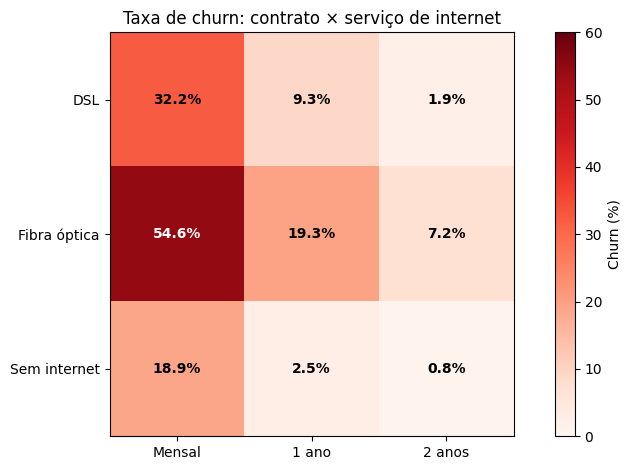

In [ ]:
hm = (pd.crosstab(df.InternetService, df.Contract, df.Churn == "Yes",
                  aggfunc="mean") * 100).loc[ordem, ["Month-to-month", "One year", "Two year"]]

fig, ax = plt.subplots(figsize=(8.5, 4.8))
im = ax.imshow(hm.values, cmap="Reds", vmin=0, vmax=60)
ax.set_xticks(range(3)); ax.set_xticklabels(["Mensal", "1 ano", "2 anos"])
ax.set_yticks(range(3)); ax.set_yticklabels(["DSL", "Fibra óptica", "Sem internet"])
for i in range(3):
    for j in range(3):
        v = hm.values[i, j]
        ax.text(j, i, f"{v:.1f}%", ha="center", va="center",
                color="white" if v > 35 else "black", fontweight="bold")
ax.set_title("Taxa de churn: contrato × serviço de internet")
plt.colorbar(im, label="Churn (%)")
plt.tight_layout(); plt.show()

O perfil do cliente com alta probabilidade de cancelamento é caracterizado por novos usuários nos primeiros 12 meses de contrato (baixo tenure), vinculados ao plano mensal (Month-to-month), e que possuem mensalidades elevadas, sobretudo no serviço de Fibra Óptica sem contratação de serviços adicionais como Suporte Técnico. A análise integrada evidencia que a evasão é fortemente concentrada no início do ciclo de vida do cliente (Gráfico 1), impulsionada pela ausência de barreiras contratuais de permanência — onde contratos de 1 e 2 anos reduzem drasticamente o churn (Gráfico 2). Além disso, o custo financeiro atua como um gatilho direto: os clientes que cancelam o serviço de Fibra Óptica pagam os maiores valores médios da base (Gráfico 3), o que reflete uma percepção desfavorável de custo-benefício. Essa insatisfação é intensificada pela falta de suporte adequado, visto que a taxa de saída cai significativamente entre usuários que possuem suporte técnico ativo (Gráfico 4). Assim, a combinação de preço alto no serviço premium, ausência de contrato de longo prazo e falta de suporte cria a tempestade perfeita para a evasão do cliente.

#### Gênero do Cliente

Conforme a documentação da base de dados, há dois valores possíveis para o gênero do cliente, são eles:  
    - M: Masculino  
    - F: Feminino  
    
Tal como dispostos, segundo strings, essas informações não ajudam modelos que lidam apenas com dados numéricos. É necessário efetuar uma codificação para representar tais valores. Assim, codifique a coluna gender conforme a abordagem One-Hot Encoding e elimine a coluna original do dataset.

Referências:
- https://towardsdatascience.com/what-is-one-hot-encoding-and-how-to-use-pandas-get-dummies-function-922eb9bd4970
- https://scikit-learn.org/stable/modules/generated/sklearn.preprocessing.OneHotEncoder.html

In [ ]:
df['gender'].unique()

df = pd.get_dummies(df, columns=['gender'], dtype=int)
df.head()

,customerID,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,...,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn,gender_Female,gender_Male
0,7590-VHVEG,0,Yes,No,1,No,No phone service,DSL,No,Yes,...,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No,1,0
1,5575-GNVDE,0,No,No,34,Yes,No,DSL,Yes,No,...,No,No,One year,No,Mailed check,56.95,1889.50,No,0,1
2,3668-QPYBK,0,No,No,2,Yes,No,DSL,Yes,Yes,...,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes,0,1
3,7795-CFOCW,0,No,No,45,No,No phone service,DSL,Yes,No,...,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No,0,1
4,9237-HQITU,0,No,No,2,Yes,No,Fiber optic,No,No,...,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes,1,0


#### Codificação dos Atributos

- Se o atributo tiver de duas até cinco categorias, repita o processo de codificação conforme proposto anteriormente.
- Em caso contrário, elimine a coluna em questão. Essa é uma prática utilizada no escopo deste exercício, em situações reais faz-se One-Hot Encoding mantendo-se um alto número de colunas mesmo assim

- A alternativa para o One-Hot Encoding é o Label Encoding. Quais são as críticas a essa forma de codificação?

Referências:
- https://scikit-learn.org/stable/modules/generated/sklearn.preprocessing.LabelEncoder.html


In [ ]:
colunas = df.select_dtypes(include='object').columns

In [ ]:
for coluna in colunas:
  num_categorias = df[coluna].nunique()
  if 2 <= num_categorias <= 5:
    df = pd.get_dummies(df, columns=[coluna], dtype=int)
  else:
    df = df.drop(columns=[coluna])

#### O dataset é balanceado?

- Considera-se que o dataset é balanceado se não houver mais de 10% de diferença no quantitativo das classes nele presentes. Faça a avaliação nesses termos. Elabore gráficos que justificam sua resposta.
- A partir da resposta considerada, apresente quatro métricas de desempenho a serem utilizadas na avaliação comparativa de modelos para esse problema

In [ ]:
quant_churn = df['Churn_Yes'].value_counts()

porcent_churn = df['Churn_Yes'].value_counts(normalize=True) * 100

print("Frequência absoluta:")
print(quant_churn)
print("\nFrequência relativa (%):")
print(porcent_churn.round(2))

Frequência absoluta:
Churn_Yes
0    5163
1    1869
Name: count, dtype: int64

Frequência relativa (%):
Churn_Yes
0    73.42
1    26.58
Name: proportion, dtype: float64


Verificar se dataset está ou não balanceado

In [ ]:
diferenca = porcent_churn.max() - porcent_churn.min()

if diferenca <= 10:
  print("Dataset balanceado (critério dos 10%)")
else:
  print("Dataset desbalanceado (critério dos 10%)")

Dataset desbalanceado (critério dos 10%)


Gráfico

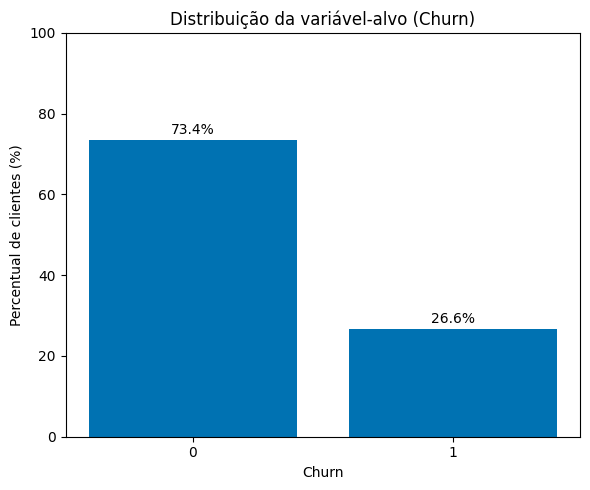

In [ ]:
fig, ax = plt.subplots(figsize=(6, 5))

barras = ax.bar(porcent_churn.index.astype(str), porcent_churn.values, color="#0072B2")

ax.set_xlabel("Churn")
ax.set_ylabel("Percentual de clientes (%)")
ax.set_ylim(0, 100)
ax.set_title("Distribuição da variável-alvo (Churn)")

for barra, valor in zip(barras, porcent_churn.values):
    ax.text(barra.get_x() + barra.get_width()/2, valor + 1.5, f"{valor:.1f}%", ha='center')

plt.tight_layout()
plt.show()

Métricas de Desempenho a serem utilizadas: Recall, Precisão e F1-Score

## Parte 2 - Tarefa de Aprendizado de Máquina

Abordaremos o problema da previsão de churn como uma tarefa de classificação binária.

#### Preparação dos dados para Validação Cruzada Holdout

- Vamos separar o atributo alvo (tenure) dos atributores preditores.
  - Atributos preditores devem ser armazenados em uma variável denominada X  
  - Atributo alvo deve ser armazenado em uma variável denominada y
  - Garanta que o atributo alvo não está nos atributos preditores
- Qual o tipo de entrada do modelo?
- Vamos efetuar uma partição do tipo holdout estratificada 70/30
  - Quais as características de uma partição estratificada?

Documentação completa disponível em: https://scikit-learn.org/stable/modules/generated/sklearn.model_selection.train_test_split.html

In [ ]:
X = df.drop(columns=['Churn_No', 'Churn_Yes'])
y = df['Churn_Yes']

from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.30,
    stratify=y,
    random_state=42
)


#### Treinar um modelo de regressão logística para o problema

A Regressão Logística é uma técnica de Aprendizado de Máquina que tem como objetivo produzir, a partir de um conjunto de observações, um modelo que permita a predição de valores tomados por uma variável categórica, frequentemente binária, a partir de uma série de variáveis explicativas.

1. Importe o modelo da biblioteca sklearn
2. Instancie o modelo com parâmetros padrão (default)
3. Execute o algoritmo de treinamento com os dados de treino

Documentação completa disponível em: https://scikit-learn.org/stable/modules/generated/sklearn.linear_model.LogisticRegression.html

In [ ]:
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

modelo = LogisticRegression()
modelo.fit(X_train_scaled, y_train)

LogisticRegression()

#### Obtendo previsões do modelo

1. Selecione um exemplo arbitrário da partição de teste
2. Forneça os atributos preditores e obtenha a previsão da churn
3. O modelo previu a saída corretamente?

In [ ]:
import numpy as np

indice = np.random.randint(0, len(X_test))
exemplo = X_test_scaled[indice].reshape(1, -1)

previsao = modelo.predict(exemplo)[0]
saida_real = y_test.iloc[indice]

print(f"Saída real: {saida_real}")
print(f"Previsão do modelo: {previsao}")
print("Acertou! " if previsao == saida_real else "Errou. ")

Saída real: 0
Previsão do modelo: 0
Acertou! 


#### Avalie o modelo perante o conjunto de testes

1. Obtenha as métricas elencadas para o conjunto de testes
  * Efetue a importação de tais métricas a partir do pacote sklearn.metrics
2. Elabore uma visualização da matriz de confusão normalizada para as previsões do conjunto de testes
3. O modelo é bom para o problema? Justifique sua afirmação.

In [ ]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

y_pred = modelo.predict(X_test_scaled)

acuracia = accuracy_score(y_test, y_pred)
precisao = precision_score(y_test, y_pred)
recall = recall_score(y_test, y_pred)
f1 = f1_score(y_test, y_pred)


print(f"Acurácia: {acuracia:.4f}")
print(f"Precisão: {precisao:.4f}")
print(f"Recall:   {recall:.4f}")
print(f"F1-score: {f1:.4f}")

Acurácia: 0.8062
Precisão: 0.6570
Recall:   0.5668
F1-score: 0.6086


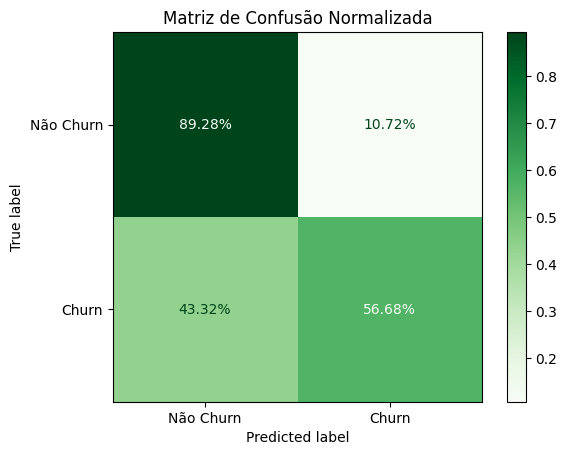

In [ ]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

cm = confusion_matrix(y_test, y_pred, normalize='true')
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=['Não Churn', 'Churn'])
disp.plot(cmap='Greens', values_format='.2%')
plt.title('Matriz de Confusão Normalizada')
plt.show()

o modelo tem desempenho moderado, mas insuficiente para o problema real. Como o objetivo prático é identificar clientes propensos a cancelar (para ações de retenção), o recall baixo (0,57) é o ponto mais crítico, significa que a empresa perderia quase metade dos clientes em risco sem nenhum alerta. A acurácia alta (0,81) é enganosa, puxada pelo desbalanceamento das classes (mais clientes ficam do que saem), então não deve ser usada isoladamente para avaliar o modelo,é perceptível que o modelo na verdade está em viés para a classe majoritária de não churn, ou seja, acaba não sendo muito bom para essa atividade em específico.

#### Treinar um modelo de K-Vizinhos Mais Próximos

É um algoritmo de Aprendizado de Máquina que baseia-se na média dos valores dos k vizinhos mais próximos a uma dada entrada para produzir uma estimativa para o atributo-alvo. É considerado "preguiçoso", mas muito mostra-se vantajoso por possuir um baixo custo computacional.

1. Efetue o treinamento do K-Vizinhos mais Próximos, considerando k = 5
2. Efetue o teste no modelo e obtenha as métricas de desempenho previamente indicadas.  

In [ ]:
##PEDAÇO DE CODIGO PRA FACILITAR AVALIAÇÕES
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                              f1_score, confusion_matrix)

resultados = {}

def avaliar_modelo(nome, y_true, y_pred):
    resultados[nome] = {
        'acuracia': accuracy_score(y_true, y_pred),
        'precisao': precision_score(y_true, y_pred),
        'recall': recall_score(y_true, y_pred),
        'f1': f1_score(y_true, y_pred),
        'matriz': confusion_matrix(y_true, y_pred, normalize='true')
    }
    print(f"--- {nome} ---")
    for k, v in resultados[nome].items():
        if k != 'matriz':
            print(f"{k}: {v:.4f}")



In [ ]:
from sklearn.neighbors import KNeighborsClassifier

knn = KNeighborsClassifier(n_neighbors=5)
knn.fit(X_train_scaled, y_train)

y_pred_knn = knn.predict(X_test_scaled)
avaliar_modelo('KNN (k=5)', y_test, y_pred_knn)

--- KNN (k=5) ---
acuracia: 0.7412
precisao: 0.5130
recall: 0.5258
f1: 0.5194


#### Treinar um modelo de Árvore de Decisão

É um modelo de aprendizado de máquina supervisionado, utilizado para problemas de classificação e regressão. Sua estrutura se assemelha a um fluxograma, em que cada nó interno representa um teste em uma atributo dado, cada ramo corresponde a um resultado desse teste, e cada nó folha a uma decisão final ou previsão. Destaca-se por sua interpretabilidade

1. Efetue o treinamento do Árvore de Decisão, utilizando o critério de entropia.
2. Efetue o teste no modelo e obtenha as métricas de desempenho previamente indicadas.  
3. Plote a árvore de decisão construída.

--- Árvore de Decisão ---
acuracia: 0.7161
precisao: 0.4661
recall: 0.4652
f1: 0.4657


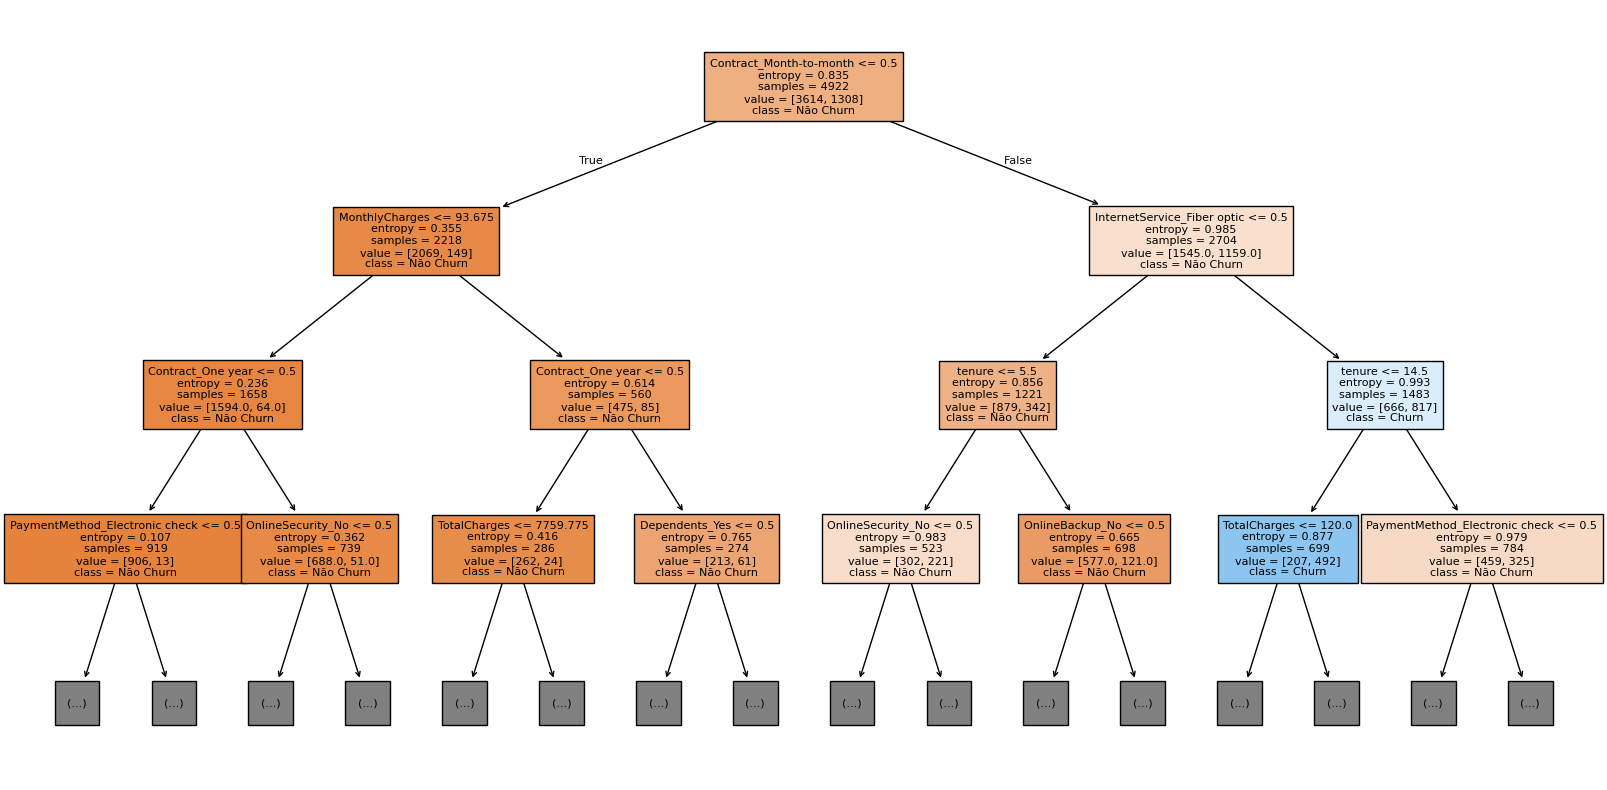

In [ ]:
from sklearn.tree import DecisionTreeClassifier, plot_tree
import matplotlib.pyplot as plt

arvore = DecisionTreeClassifier(criterion='entropy', random_state=42)
arvore.fit(X_train, y_train)

y_pred_arvore = arvore.predict(X_test)
avaliar_modelo('Árvore de Decisão', y_test, y_pred_arvore)

plt.figure(figsize=(20,10))
plot_tree(arvore, feature_names=X.columns, class_names=['Não Churn', 'Churn'],
          filled=True, max_depth=3, fontsize=8)
plt.show()

#### Síntese dos Resultados

- Agrupe as matrizes de confusão obtidas lado a lado
- Crie uma tabela com todos os modelos e métricas (Pretty Table)

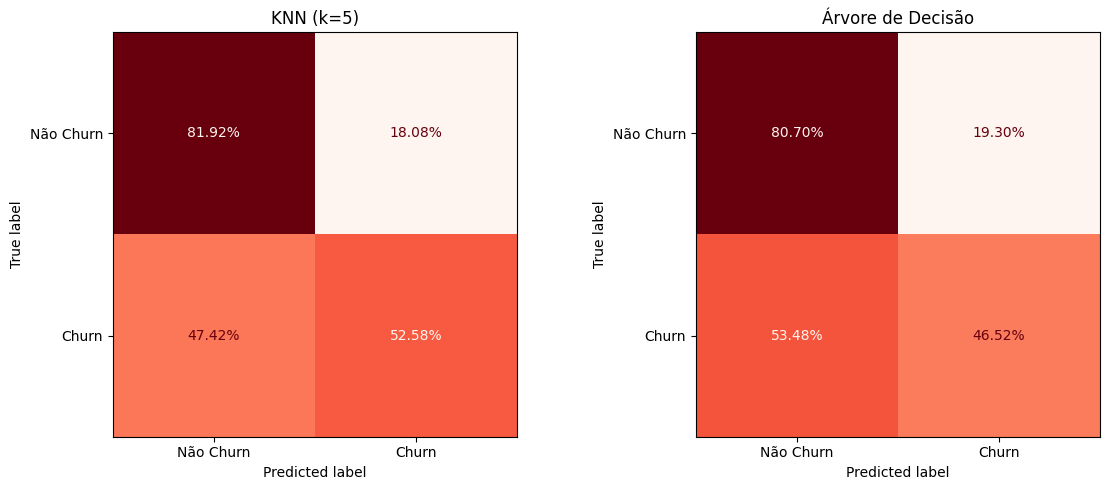

In [ ]:
from sklearn.metrics import ConfusionMatrixDisplay

fig, axes = plt.subplots(1, len(resultados), figsize=(6*len(resultados), 5))
for ax, (nome, dados) in zip(axes, resultados.items()):
    disp = ConfusionMatrixDisplay(confusion_matrix=dados['matriz'],
                                    display_labels=['Não Churn', 'Churn'])
    disp.plot(ax=ax, cmap='Reds', values_format='.2%', colorbar=False)
    ax.set_title(nome)
plt.tight_layout()
plt.show()

In [ ]:
from prettytable import PrettyTable

tabela = PrettyTable()
tabela.field_names = ['Modelo', 'Acurácia', 'Precisão', 'Recall', 'F1-score']
for nome, dados in resultados.items():
    tabela.add_row([
        nome,
        f"{dados['acuracia']:.4f}",
        f"{dados['precisao']:.4f}",
        f"{dados['recall']:.4f}",
        f"{dados['f1']:.4f}"
    ])
print(tabela)

+-------------------+----------+----------+--------+----------+
|       Modelo      | Acurácia | Precisão | Recall | F1-score |
+-------------------+----------+----------+--------+----------+
|     KNN (k=5)     |  0.7412  |  0.5130  | 0.5258 |  0.5194  |
| Árvore de Decisão |  0.7161  |  0.4661  | 0.4652 |  0.4657  |
+-------------------+----------+----------+--------+----------+


#### Argumente

- Qual o melhor modelo para o problema em questão?
- Qual o grau de dificuldade da tarefa de aprendizado proposta? Justifique a partir dos elementos e resultados obtidos nas células anteriores.

Considerando que o objetivo prático da tarefa é identificar clientes com risco de cancelamento (churn), a métrica mais relevante para comparação não é a acurácia, mas sim o **recall da classe Churn**,isto é, a proporção de clientes que realmente cancelaram e que o modelo conseguiu identificar corretamente. Sob esse critério, a **Regressão Logística** apresentou o melhor desempenho, com recall de 56,68%, seguida pelo KNN (k=5), com 52,58%, e pela Árvore de Decisão, com apenas 46,52%, a pior das três, errando mais da metade dos casos de churn ao classificá-los como "Não Churn". Esse resultado é coerente com o comportamento esperado de uma árvore de decisão sem restrição de profundidade ou poda: o modelo tende a se ajustar fortemente ao padrão da classe majoritária presente no conjunto de treino, prejudicando sua capacidade de generalização para a classe minoritária. É importante ressaltar, no entanto, que nenhum dos três modelos apresentou desempenho satisfatório para uso prático: mesmo o melhor deles (Regressão Logística) ainda deixa de identificar 43% dos clientes que efetivamente cancelam. Isso indica que a limitação observada não está associada a um algoritmo específico, mas sim às características do problema e dos dados utilizados.A tarefa pode ser classificada como de dificuldade **moderada a alta**. Esse julgamento se apoia principalmente no fato de que três algoritmos de naturezas distintas, um modelo linear (Regressão Logística), um modelo baseado em distância (KNN) e um modelo baseado em regras de decisão (Árvore de Decisão), convergiram para uma faixa de desempenho semelhante (recall entre 46% e 57%), sem que nenhum se destacasse de forma expressiva. Essa convergência sugere que o teto de desempenho está sendo limitado pelas características dos dados e atributos disponíveis, e não pela escolha do algoritmo de aprendizado.
Contribui ainda para essa dificuldade o desbalanceamento das classes no conjunto de dados (número de clientes que não cancelam consideravelmente maior do que os que cancelam), o que leva os modelos a favorecerem a previsão da classe majoritária diante de incerteza, prejudicando justamente a identificação da classe de maior interesse prático (Churn). Isso indica que, para obter ganhos reais de desempenho, seria mais produtivo investir em técnicas de tratamento do desbalanceamento ou enriquecimento dos atributos preditores, em vez de simplesmente experimentar novos algoritmos de classificação.